# 02 - Análisis exploratorio de datos (EDA)

## Objetivo

Realizar un análisis exploratorio del dataset Chronic Kidney Disease para comprender su estructura, caracterizar las variables y explorar posibles relaciones entre ellas.

Se analizarán las distribuciones de las variables numéricas y categóricas, la presencia de datos faltantes y posibles valores atípicos.

El análisis permitirá identificar patrones y características relevantes del dataset.

In [239]:
# 1. Importar bibliotecas
import sys
from pathlib import Path
import importlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Encontrar automáticamente la raíz del proyecto
PROJECT_ROOT = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "helpers").is_dir():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró la carpeta 'helpers'. "
        "Verificá desde qué directorio se está ejecutando la notebook."
    )


# 3. Agregar la raíz del proyecto a las rutas de búsqueda
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# 4. Definir las rutas de los archivos
PROCESSED_PATH = (PROJECT_ROOT/ "data"/ "processed"/ "chronic_kidney_disease_fixed.arff"
)

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Dataset: {PROCESSED_PATH}")

# 5. Importar y recargar el helper de EDA
import helpers.eda_utils
importlib.reload(helpers.eda_utils)

from helpers.eda_utils import (
    load_arff_dataset,
    decode_categorical_values,
    replace_missing_values,
    set_variable_types,
    classify_skewness,
    classify_kurtosis,
    calculate_shannon_entropy
)

import helpers.funciones_visualizacion_EDA
importlib.reload(helpers.funciones_visualizacion_EDA)

from helpers.funciones_visualizacion_EDA import (
    plot_distribution,
    plot_boxplot,
    plot_categorical_bar_distribution,
    plot_categorical_pie
)

Raíz del proyecto: c:\Users\Meli\OneDrive\Documentos\Maestría IA\Especialización IA\CEIA_AndD\Chronic-Kidney-Disease-EDA-ActividadIndividual2-Piacentino
Dataset: c:\Users\Meli\OneDrive\Documentos\Maestría IA\Especialización IA\CEIA_AndD\Chronic-Kidney-Disease-EDA-ActividadIndividual2-Piacentino\data\processed\chronic_kidney_disease_fixed.arff


## 1. Inspección general del dataset

Se carga el dataset acondicionado en `01_acondicionamiento_dataset.ipynb` para realizar una primera inspección de su estructura y contenido.

Se revisan sus dimensiones, los nombres de las variables, los primeros registros y los tipos de datos asignados por Pandas.

### 1.1. Carga del dataset

Para comenzar el análisis exploratorio, se cargó el archivo ARFF previamente acondicionado y se convirtió su contenido a un DataFrame de pandas mediante la función `load_arff_dataset()`, definida en el módulo `helpers/eda_utils.py`.

Esta función realiza las siguientes operaciones:

1. **Lectura del archivo ARFF:** lee el contenido del archivo e identifica el comienzo de la sección de datos.
2. **Normalización del formato:** elimina espacios sobrantes al principio y al final de los campos para evitar inconsistencias durante la interpretación de los valores.
3. **Conversión a DataFrame:** utiliza `scipy.io.arff.loadarff()` para interpretar el archivo ARFF y obtener los registros, que posteriormente se convierten en un DataFrame de pandas.

In [240]:
# 6. Cargar el dataset procesado
cdk_df = load_arff_dataset(PROCESSED_PATH)

print("Dataset cargado correctamente.")
print(f"Dimensiones: {cdk_df.shape[0]} registros y {cdk_df.shape[1]} variables.")
cdk_df.head()

Dataset cargado correctamente.
Dimensiones: 400 registros y 25 variables.


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,b'1.020',b'1',b'0',b'?',b'normal',b'notpresent',b'notpresent',121.0,...,44.0,7800.0,5.2,b'yes',b'yes',b'no',b'good',b'no',b'no',b'ckd'
1,7.0,50.0,b'1.020',b'4',b'0',b'?',b'normal',b'notpresent',b'notpresent',NaN,...,38.0,6000.0,NaN,b'no',b'no',b'no',b'good',b'no',b'no',b'ckd'
2,62.0,80.0,b'1.010',b'2',b'3',b'normal',b'normal',b'notpresent',b'notpresent',423.0,...,31.0,7500.0,NaN,b'no',b'yes',b'no',b'poor',b'no',b'yes',b'ckd'
3,48.0,70.0,b'1.005',b'4',b'0',b'normal',b'abnormal',b'present',b'notpresent',117.0,...,32.0,6700.0,3.9,b'yes',b'no',b'no',b'poor',b'yes',b'yes',b'ckd'
4,51.0,80.0,b'1.010',b'2',b'0',b'normal',b'normal',b'notpresent',b'notpresent',106.0,...,35.0,7300.0,4.6,b'no',b'no',b'no',b'good',b'no',b'no',b'ckd'


Al visualizar los primeros registros del DataFrame mediante df.head(), se observa que los valores faltantes se representan de manera diferente según el tipo de variable: en las variables categóricas aparecen como `?`, mientras que en las numéricas se muestran como `NaN`.

### 1.2. Decodificación de variables categóricas

Al cargar el archivo ARFF, los valores de las variables categóricas pueden quedar almacenados como secuencias de bytes (`bytes`) en lugar de cadenas de texto (`str`).

Para facilitar su manipulación y análisis mediante pandas, se implementó la función `decode_categorical_values()`, que identifica las columnas de tipo `object` y convierte los valores almacenados como bytes a cadenas de texto mediante su decodificación con UTF-8.

Esta operación modifica la representación de los valores en memoria, sin alterar el contenido de las categorías.

In [241]:
cdk_df = decode_categorical_values(cdk_df)

print("Variables categóricas decodificadas correctamente.")

Variables categóricas decodificadas correctamente.


### 1.3. Conversión de valores faltantes

En el archivo ARFF original, se representan mediante el símbolo `?`. Para facilitar su identificación y posterior análisis con pandas, se implementó la función `replace_missing_values()`, que reemplaza esta representación por `NaN`.

In [242]:
cdk_df = replace_missing_values(cdk_df)

print("Valores faltantes convertidos correctamente.")
cdk_df.head()

Valores faltantes convertidos correctamente.


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1,0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4,0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2,3,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4,0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2,0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


## 2. Descripción y clasificación de las variables

El dataset contiene 25 variables: 24 atributos que describen características clínicas y resultados de laboratorio de los pacientes, y una variable objetivo (`class`) que indica la presencia o ausencia de enfermedad renal crónica.

A partir de la documentación proporcionada por UCI, se identificaron las variables y se clasificaron según su naturaleza. Para las variables numéricas, se distingue entre discretas (`Integer`) y continuas (`Continuous`). Las variables categóricas se clasifican en ordinales y nominales, según la existencia o no de un orden entre sus categorías.

| Variable | Tipo de variable | Descripción |
|---|---|---|
| `age` | Numérica discreta (Integer) | Edad del paciente (años). |
| `bp` | Numérica discreta (Integer) | Presión arterial (mmHg). |
| `sg` | Categórica ordinal | Gravedad específica. |
| `al` | Categórica ordinal | Nivel de albúmina. |
| `su` | Categórica ordinal | Nivel de azúcar. |
| `rbc` | Categórica nominal (Binary) | Características de los glóbulos rojos: normales o anormales. |
| `pc` | Categórica nominal (Binary) | Características de las células de pus: normales o anormales. |
| `pcc` | Categórica nominal (Binary) | Presencia o ausencia de agrupaciones de células de pus. |
| `ba` | Categórica nominal (Binary) | Presencia o ausencia de bacterias. |
| `bgr` | Numérica discreta (Integer) | Glucemia aleatoria (mg/dL). |
| `bu` | Numérica discreta (Integer) | Urea en sangre (mg/dL). |
| `sc` | Numérica continua (Continuous) | Creatinina sérica (mg/dL). |
| `sod` | Numérica discreta (Integer) | Concentración de sodio (mEq/L). |
| `pot` | Numérica continua (Continuous) | Concentración de potasio (mEq/L). |
| `hemo` | Numérica continua (Continuous) | Concentración de hemoglobina (g/dL). |
| `pcv` | Numérica discreta (Integer) | Volumen celular empaquetado. |
| `wbcc` | Numérica discreta (Integer) | Recuento de glóbulos blancos (células/mm³). |
| `rbcc` | Numérica continua (Continuous) | Recuento de glóbulos rojos (millones/mm³). |
| `htn` | Categórica nominal (Binary) | Presencia o ausencia de hipertensión. |
| `dm` | Categórica nominal (Binary) | Presencia o ausencia de diabetes mellitus. |
| `cad` | Categórica nominal (Binary) | Presencia o ausencia de enfermedad arterial coronaria. |
| `appet` | Categórica nominal (Binary) | Apetito: bueno o malo. |
| `pe` | Categórica nominal (Binary) | Presencia o ausencia de edema periférico. |
| `ane` | Categórica nominal (Binary) | Presencia o ausencia de anemia. |
| `class` | Categórica nominal (objetivo) | Clasificación del paciente: enfermedad renal crónica (`ckd`) o ausencia de enfermedad renal crónica (`notckd`). |

En total, se identificaron:
- **7 variables numéricas discretas.**
- **4 variables numéricas continuas.**
- **3 variables categóricas ordinales:** `sg`, `al` y `su`.
- **11 variables categóricas nominales**, incluyendo la variable objetivo `class`.


**Criterio de clasificación de las variables ordinales:**

Aunque UCI clasifica originalmente las variables `sg`, `al` y `su` como categóricas nominales, en este análisis se decidió tratarlas como categóricas ordinales debido a la naturaleza de sus valores:

- `sg` (Specific Gravity): presenta cinco categorías numéricas ordenadas de menor a mayor [1.005, 1.010, 1.015, 1.020 y 1.025].
- `al` (Albumin): presenta seis categorías ordenadas de 0 a 5.
- `su` (Sugar): presenta seis categorías ordenadas de 0 a 5.

Por este motivo, se considera que estas variables presentan un orden inherente entre sus categorías, aunque no se asume que las diferencias entre categorías consecutivas sean equivalentes.

In [243]:
# Se verifica el dtype que asigno Padas:
cdk_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    object 
 3   al      354 non-null    object 
 4   su      351 non-null    object 
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-null    object 
 22  pe

Se identifican y agrupan las variables del dataset según su naturaleza

In [244]:
# Variables categóricas ordinales y sus categorías ordenadas
ordinal_categories = {
    "sg": ["1.005", "1.010", "1.015", "1.020", "1.025"],
    "al": ["0", "1", "2", "3", "4", "5"],
    "su": ["0", "1", "2", "3", "4", "5"]
    }

# Variables categóricas nominales serán el resto de las variables
nominal_categories = cdk_df.select_dtypes(include=["object"]).columns.difference(ordinal_categories.keys())

# Variables numéricas discretas (Integer)
discrete_columns = [
    "age", "bp", "bgr", "bu", "sod", "pcv", "wbcc"
]

# Variables numéricas continuas (Continuous)
continuous_columns = [
    "sc", "pot", "hemo", "rbcc"
]


Posteriormente, se utilizó la función `set_variable_types()`, definida en `helpers/eda_utils.py`, para ajustar los tipos de datos en pandas:

- Las variables numéricas se convirtieron a `float64`.
- Las variables categóricas nominales se convirtieron a `category`.
- Las variables categóricas ordinales se convirtieron a `category`, estableciendo el orden de sus categorías.

Además, se verificó que los valores de las variables ordinales pertenezcan a las categorías definidas.

In [245]:
numeric_columns = discrete_columns + continuous_columns # Todas las variables numéricas

cdk_df = set_variable_types(cdk_df, numeric_columns, ordinal_categories, nominal_categories)
cdk_df.dtypes

age       float64
bp        float64
sg       category
al       category
su       category
rbc      category
pc       category
pcc      category
ba       category
bgr       float64
bu        float64
sc        float64
sod       float64
pot       float64
hemo      float64
pcv       float64
wbcc      float64
rbcc      float64
htn      category
dm       category
cad      category
appet    category
pe       category
ane      category
class    category
dtype: object

In [246]:
print("Categorías de sg:", cdk_df["sg"].dropna().unique())
print("Categorías de al:", cdk_df["al"].dropna().unique())
print("Categorías de su:", cdk_df["su"].dropna().unique())

Categorías de sg: ['1.020', '1.010', '1.005', '1.015', '1.025']
Categories (5, object): ['1.005' < '1.010' < '1.015' < '1.020' < '1.025']
Categorías de al: ['1', '4', '2', '3', '0', '5']
Categories (6, object): ['0' < '1' < '2' < '3' < '4' < '5']
Categorías de su: ['0', '3', '4', '1', '2', '5']
Categories (6, object): ['0' < '1' < '2' < '3' < '4' < '5']


## 2. Estadística descriptiva

### 2.1. Exploración de VARIABLES NUMÉRICAS

#### 2.1.1. Variables Continuas

Se analizaron las variables sc, pot, hemo y rbcc mediante estadísticos descriptivos, histogramas, medidas de asimetría y curtosis, y diagramas de caja (boxplots), con el objetivo de caracterizar sus distribuciones e identificar posibles valores atípicos.

**Medidas de tendencia central, Medidas de dispersión y cuantiles:**

In [247]:
# Estadística descriptiva de variables continuas
numeric_continuous_description = cdk_df[continuous_columns].describe().T
# Renombrar la mediana
numeric_continuous_description = numeric_continuous_description.rename(columns={"50%": "median"})
# Calcular rango intercuartílico
numeric_continuous_description["IQR"] = (numeric_continuous_description["75%"] - numeric_continuous_description["25%"])
# Calcular cantidad de valores faltantes
numeric_continuous_description["missing"] = (cdk_df[continuous_columns].isna().sum())
# Redondeamos los valores a 2 decimales
numeric_continuous_description.round(2)

,count,mean,std,min,25%,median,75%,max,IQR,missing
sc,383.0,3.07,5.74,0.4,0.9,1.30,2.8,76.0,1.9,17
pot,312.0,4.63,3.19,2.5,3.8,4.40,4.9,47.0,1.1,88
hemo,348.0,12.53,2.91,3.1,10.3,12.65,15.0,17.8,4.7,52
rbcc,269.0,4.71,1.03,2.1,3.9,4.80,5.4,8.0,1.5,131


En cuanto a la dispersión, sc y pot presentan rangos intercuartílicos pequeños respecto de sus rangos totales (2.5% en ambos casos), lo que indica que el 50% central de las observaciones ocupa una proporción reducida del rango observado.

Por el contrario, hemo y rbcc presentan IQR relativamente mayores (32.0% y 25.4%, respectivamente), lo que indica una distribución más extendida del 50% central respecto del rango total.

**Evaluación de asimetría y curtosis:**

Se analizaron las distribuciones de las variables `sc`, `pot`, `hemo` y `rbcc` mediante histogramas y medidas de asimetría y curtosis.

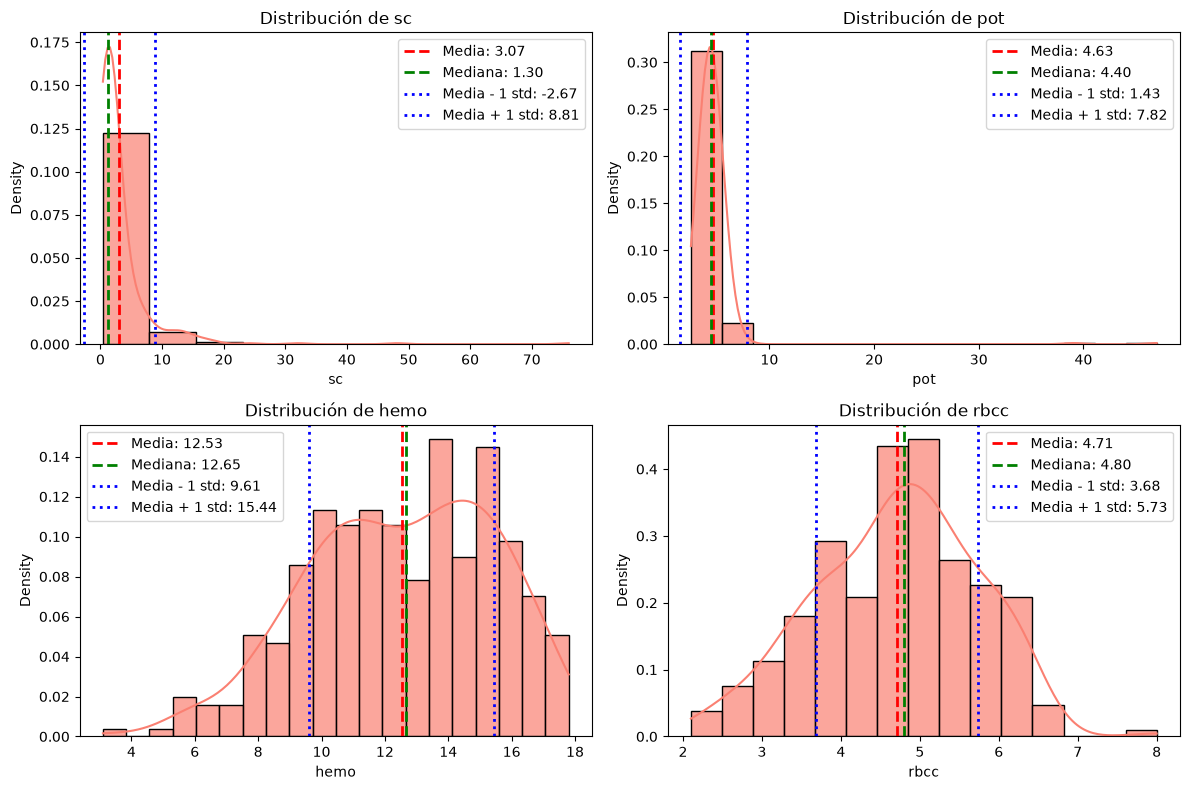

In [248]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_distribution(df=cdk_df, column="sc", bins=10, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[0, 0])
plot_distribution(df=cdk_df, column="pot", bins=15, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[0, 1])
plot_distribution(df=cdk_df, column="hemo", bins=20, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[1, 0])
plot_distribution(df=cdk_df, column="rbcc", bins=15, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [249]:
continuous_distribution = pd.DataFrame(index=continuous_columns)
continuous_distribution["skewness"] = cdk_df[continuous_columns].skew()
continuous_distribution["symmetry"] = continuous_distribution["skewness"].apply(classify_skewness)
continuous_distribution["kurtosis"] = cdk_df[continuous_columns].kurt()
continuous_distribution["kurtosis_type"] = continuous_distribution["kurtosis"].apply(lambda x: classify_kurtosis(x, tolerance=0.3))
continuous_distribution.round(3)

,skewness,symmetry,kurtosis,kurtosis_type
sc,7.510,Asimetría alta,79.304,Leptocúrtica
pot,11.583,Asimetría alta,142.506,Leptocúrtica
hemo,-0.335,Aproximadamente simétrica,-0.471,Platicúrtica
rbcc,-0.183,Aproximadamente simétrica,-0.270,Aproximadamente Mesocúrtica


- **Creatinina sérica (`sc`):** presenta una asimetría positiva muy pronunciada (7.51), con la mayoría de las observaciones concentradas en valores bajos y una cola extensa hacia la derecha. Esto explica la diferencia entre la media (3.07) y la mediana (1.30). Su curtosis extremadamente elevada (79.30) refleja la presencia de valores extremos muy alejados del centro de la distribución, lo cual se confirma en el histograma.

- **Potasio (`pot`):** presenta una asimetría positiva aún mayor (11.58), aunque la media (4.63) y la mediana (4.40) son relativamente cercanas. La mayoría de los valores se concentra en un intervalo estrecho, mientras que unas pocas observaciones alcanzan valores excepcionalmente altos. Su curtosis (142.51) es la más elevada de las cuatro variables, lo que evidencia una fuerte influencia de valores extremos. Esto último también se observa en el histograma.

- **Hemoglobina (`hemo`):** presenta una distribución aproximadamente simétrica, con una ligera asimetría negativa (-0.34), indicando una cola algo más extendida hacia los valores bajos. Su curtosis negativa (-0.47) indica una distribución ligeramente platicúrtica respecto de la normal, con menor peso en las colas según esta medida.

- **Recuento de glóbulos rojos (`rbcc`):** presenta una distribución aproximadamente simétrica, con una leve asimetría negativa (-0.18). Su curtosis cercana a cero (-0.27) indica un comportamiento mesocúrtico, relativamente similar al de una distribución normal en términos de curtosis.

**Evaluación de outliers y distribución:**

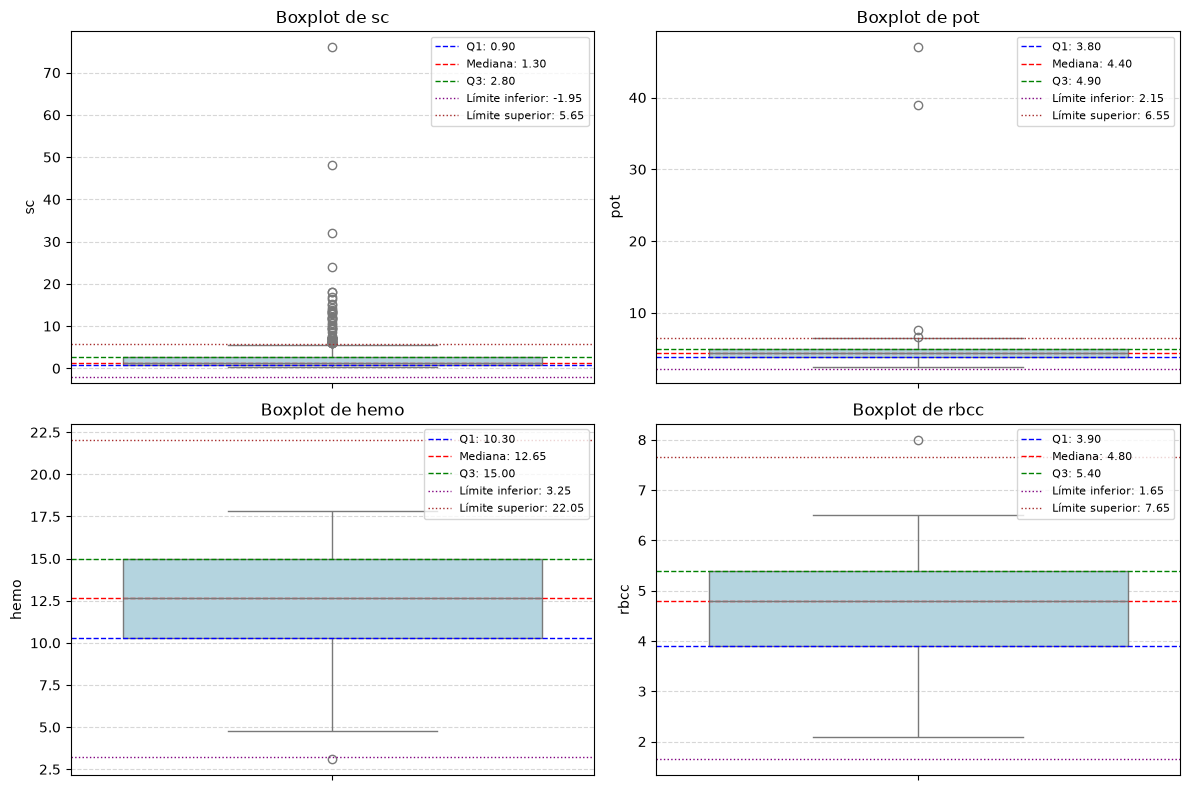

In [250]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_boxplot(df=cdk_df, column="sc", showfliers=True, show_details=True, ax=axes[0, 0])
plot_boxplot(df=cdk_df, column="pot", showfliers=True, show_details=True, ax=axes[0, 1])
plot_boxplot(df=cdk_df, column="hemo", showfliers=True, show_details=True, ax=axes[1, 0])
plot_boxplot(df=cdk_df, column="rbcc", showfliers=True, show_details=True, ax=axes[1, 1])

plt.tight_layout()
plt.show()

En conjunto, `sc` y `pot` se destacan por la presencia de valores extremos, mientras que `hemo` y `rbcc` presentan distribuciones más equilibradas y cercanas a la simetría, con pocos valores extremos.

#### 2.1.2. Variables Discretas

Se analizaron las variables age, bp, bgr, bu, sod, pcv y wbcc mediante estadísticos descriptivos, histogramas, medidas de asimetría y curtosis, y boxplots.

**Medidas de tendencia central, Medidas de dispersión y cuantiles:**

In [251]:
numeric_discrete_description = cdk_df[discrete_columns].describe().T

# Renombrar la mediana
numeric_discrete_description = numeric_discrete_description.rename(
    columns={"50%": "median"}
)

# Calcular todas las modas
numeric_discrete_description["mode"] = (
    cdk_df[discrete_columns]
    .mode()
    .apply(lambda col: col.dropna().tolist())
)

# Calcular rango intercuartílico
numeric_discrete_description["IQR"] = (
    numeric_discrete_description["75%"] -
    numeric_discrete_description["25%"]
)

# Calcular cantidad de valores faltantes
numeric_discrete_description["missing"] = cdk_df[discrete_columns].isna().sum()

# Redondear los valores a 2 decimales
numeric_discrete_description.round(2)

,count,mean,std,min,25%,median,75%,max,mode,IQR,missing
age,391.0,51.48,17.17,2.0,42.0,55.0,64.5,90.0,[60.0],22.5,9
bp,388.0,76.47,13.68,50.0,70.0,80.0,80.0,180.0,[80.0],10.0,12
bgr,356.0,148.04,79.28,22.0,99.0,121.0,163.0,490.0,[99.0],64.0,44
bu,381.0,57.43,50.50,1.5,27.0,42.0,66.0,391.0,[46.0],39.0,19
sod,313.0,137.53,10.41,4.5,135.0,138.0,142.0,163.0,[135.0],7.0,87
pcv,329.0,38.88,8.99,9.0,32.0,40.0,45.0,54.0,"[41.0, 52.0]",13.0,71
wbcc,294.0,8406.12,2944.47,2200.0,6500.0,8000.0,9800.0,26400.0,[9800.0],3300.0,106


Aplicando el criterio de considerar pequeño un IQR inferior al 20% del rango total, todas las variables presentan rangos intercuartílicos relativamente pequeños, excepto `pcv`, cuyo IQR representa aproximadamente el 28.9% de su rango.

En cuanto a los valores faltantes, destacan `wbcc` (106 registros), `sod` (87) y `pcv` (71), que presentan las mayores cantidades de datos ausentes. Estos son valores elevados teniendo en cuenta que el dataset cuenta con 400 registros.

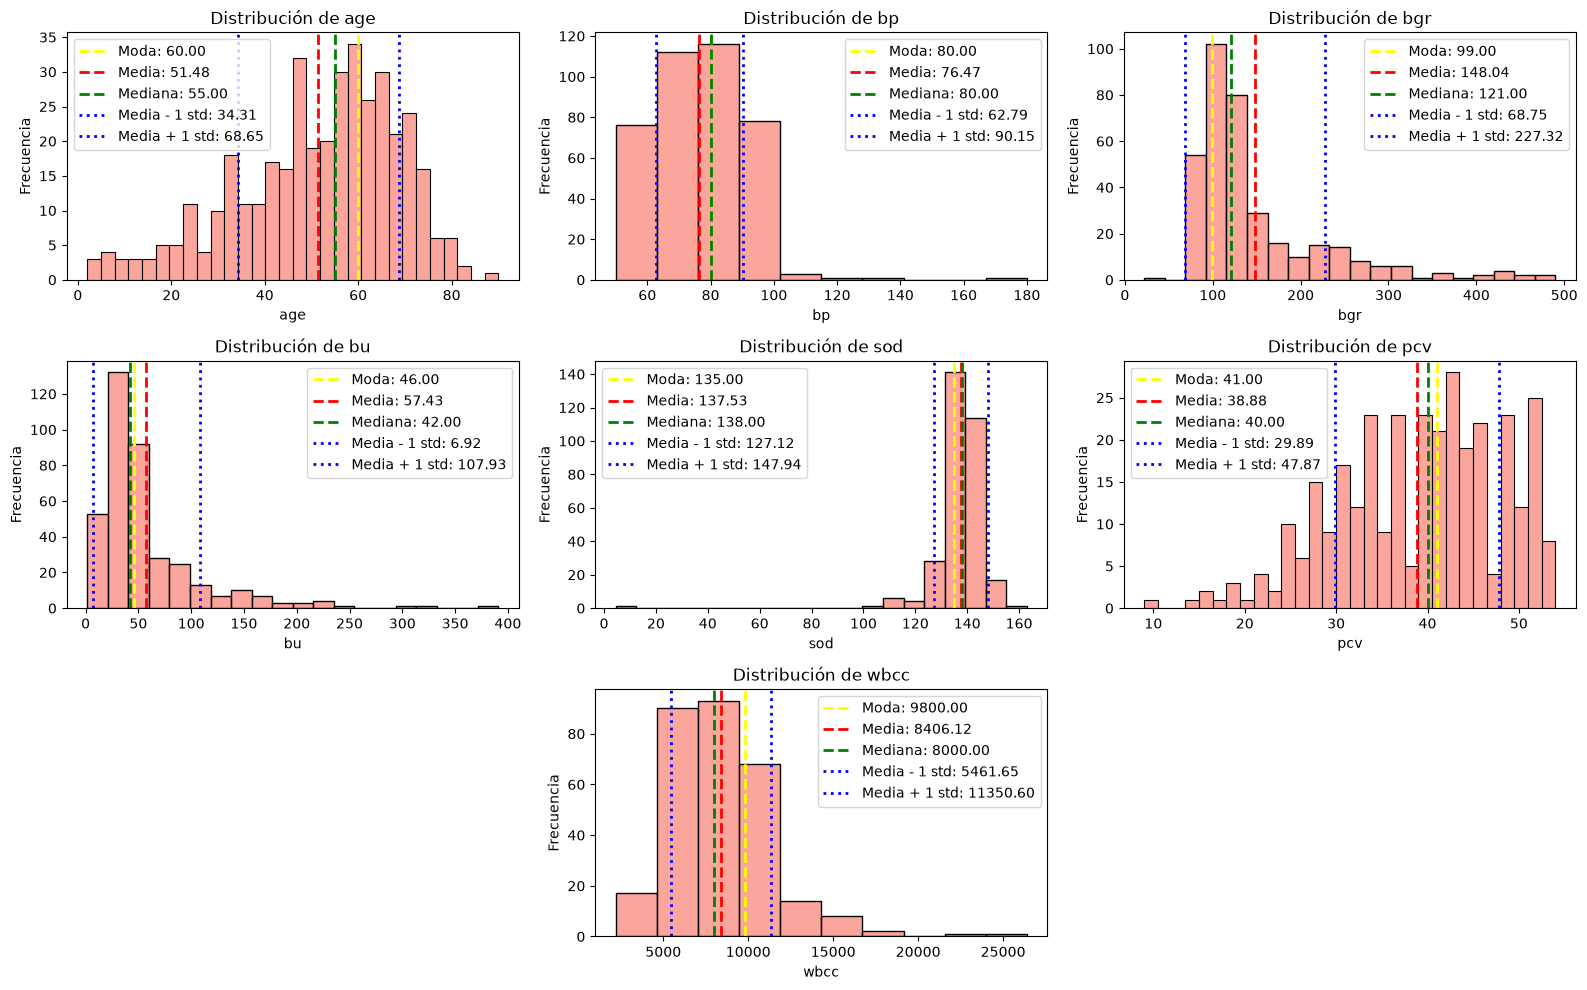

In [252]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10))

plot_distribution(df=cdk_df, column="age", bins=30, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 0])
plot_distribution(df=cdk_df, column="bp", bins=10, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 1])
plot_distribution(df=cdk_df, column="bgr", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 2])
plot_distribution(df=cdk_df, column="bu", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 0])
plot_distribution(df=cdk_df, column="sod", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 1])
plot_distribution(df=cdk_df, column="pcv", bins=30, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 2])
plot_distribution(df=cdk_df, column="wbcc", bins=10, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[2, 1])

# Ocultar los espacios sin gráficos
axes[2, 0].set_visible(False)
axes[2, 2].set_visible(False)

plt.tight_layout()
plt.show()

In [253]:
discrete_distribution = pd.DataFrame(index=discrete_columns)
discrete_distribution["skewness"] = cdk_df[discrete_columns].skew()
discrete_distribution["symmetry"] = discrete_distribution["skewness"].apply(classify_skewness)
discrete_distribution["kurtosis"] = cdk_df[discrete_columns].kurt()
discrete_distribution["kurtosis_type"] = discrete_distribution["kurtosis"].apply(lambda x: classify_kurtosis(x, tolerance=0.1))
discrete_distribution.round(3)

,skewness,symmetry,kurtosis,kurtosis_type
age,-0.668,Asimetría moderada,0.058,Aproximadamente Mesocúrtica
bp,1.605,Asimetría alta,8.646,Leptocúrtica
bgr,2.011,Asimetría alta,4.226,Leptocúrtica
bu,2.634,Asimetría alta,9.345,Leptocúrtica
sod,-6.997,Asimetría alta,85.534,Leptocúrtica
pcv,-0.434,Aproximadamente simétrica,-0.321,Platicúrtica
wbcc,1.622,Asimetría alta,6.151,Leptocúrtica


- **Edad (`age`):** presenta una asimetría negativa moderada (-0.67), con mayor concentración de observaciones en edades medias y avanzadas. Su curtosis cercana a cero (0.06) indica un comportamiento mesocúrtico.

- **Presión arterial (`bp`):** presenta una asimetría positiva elevada (1.61) y una distribución leptocúrtica (8.65), con valores concentrados principalmente entre 70 y 80.

- **Glucosa en sangre (`bgr`) y urea (`bu`):** ambas presentan asimetrías positivas pronunciadas (2.01 y 2.63, respectivamente) y curtosis elevadas (4.23 y 9.35). Sus distribuciones muestran una concentración de observaciones en valores relativamente bajos y colas extendidas hacia la derecha, con numerosos valores atípicos superiores.

- **Sodio (`sod`):** presenta una asimetría negativa extremadamente pronunciada (-7.00) y una curtosis muy elevada (85.53). Aunque la mayoría de los valores se concentra alrededor de 135–142, existen observaciones excepcionalmente bajas que afectan considerablemente las medidas descriptivas.

- **Volumen celular (`pcv`):** presenta una distribución aproximadamente simétrica, con una ligera asimetría negativa (-0.43) y curtosis negativa (-0.32), correspondiente a una distribución ligeramente platicúrtica. Se observa una dispersión relativamente equilibrada y pocos valores atípicos.

- **Recuento de glóbulos blancos (`wbcc`):** presenta una asimetría positiva elevada (1.62) y una distribución leptocúrtica (6.15), con una concentración importante de observaciones alrededor de la mediana (8000) y algunos valores extremos superiores.

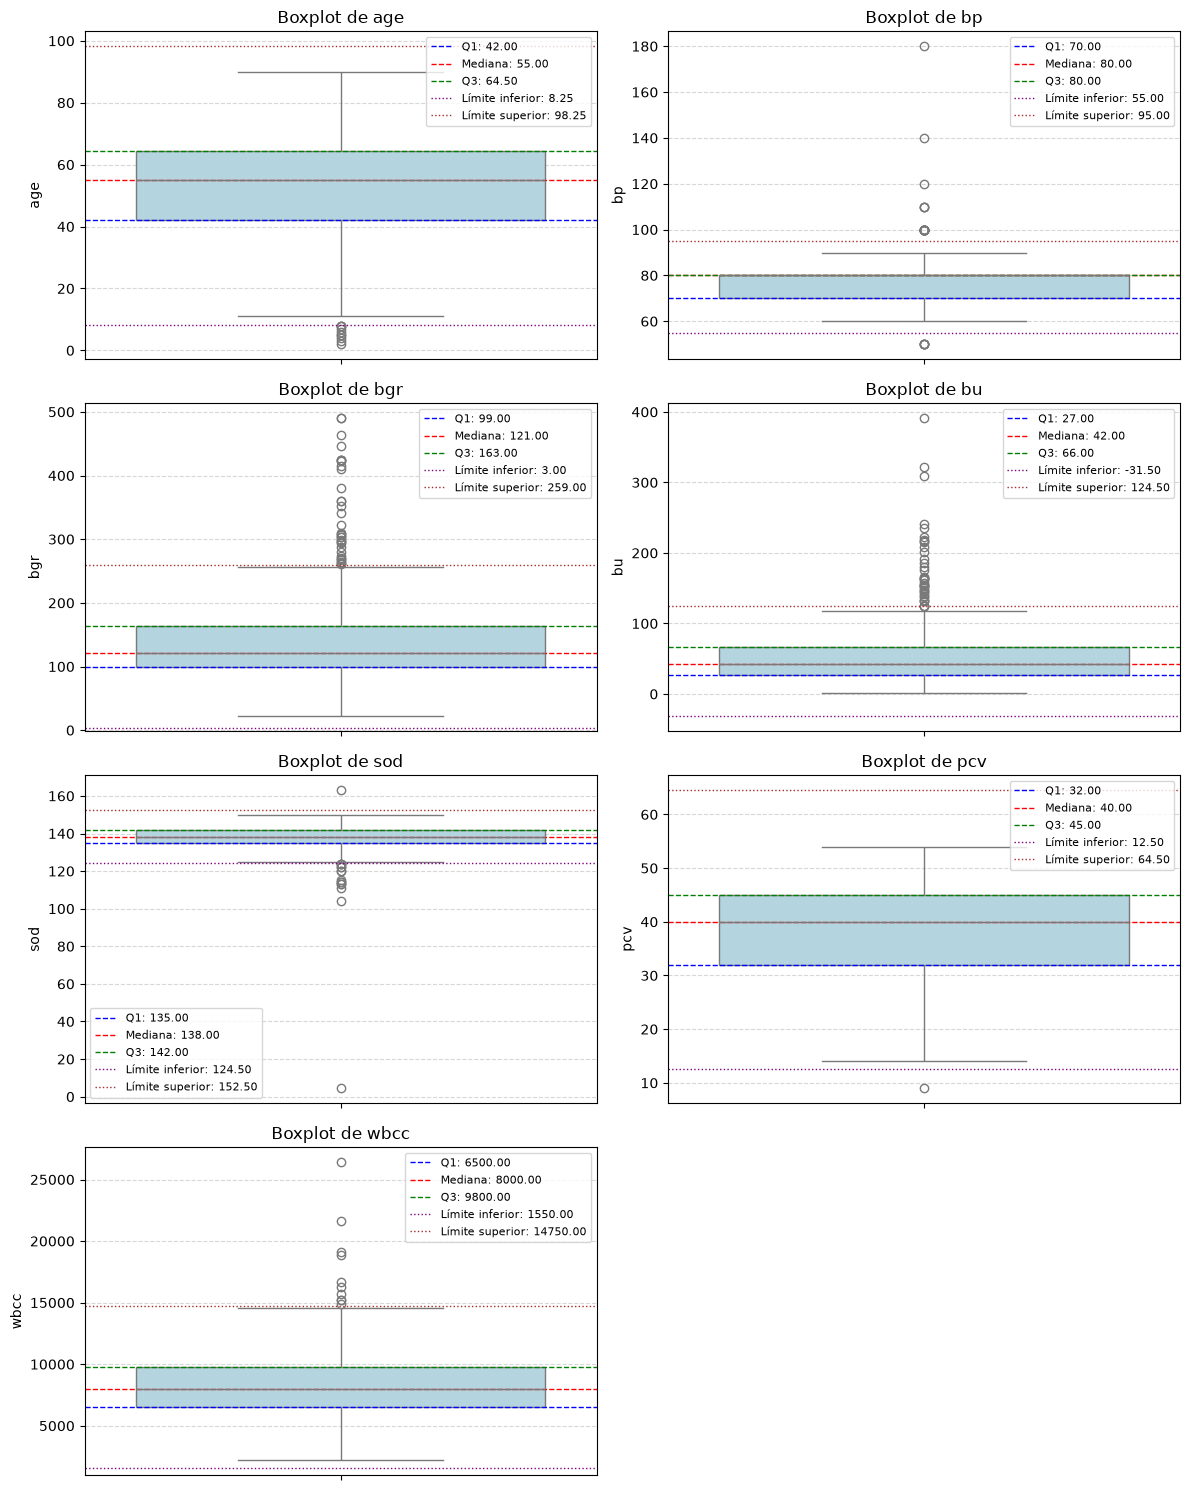

In [254]:
fig, axes = plt.subplots(4, 2, figsize=(12, 15))

plot_boxplot(df=cdk_df, column="age", showfliers=True, show_details=True, ax=axes[0, 0])
plot_boxplot(df=cdk_df, column="bp", showfliers=True, show_details=True, ax=axes[0, 1])
plot_boxplot(df=cdk_df, column="bgr", showfliers=True, show_details=True, ax=axes[1, 0])
plot_boxplot(df=cdk_df, column="bu", showfliers=True, show_details=True, ax=axes[1, 1])
plot_boxplot(df=cdk_df, column="sod", showfliers=True, show_details=True, ax=axes[2, 0])
plot_boxplot(df=cdk_df, column="pcv", showfliers=True, show_details=True, ax=axes[2, 1])
plot_boxplot(df=cdk_df, column="wbcc", showfliers=True, show_details=True, ax=axes[3, 0])

# Ocultar los espacios sin gráficos
axes[3, 1].set_visible(False)

plt.tight_layout()
plt.show()


En conjunto, predominan las distribuciones asimétricas y con una gran cantidad de valores extremos, especialmente en `bgr`, `bu` y `sod`.

### 2.2. Exploración de VARIABLES CATEGÓRICAS

#### 2.2.1. Variables categoricas nominales

Se analizaron las distribuciones de las variables categóricas nominales mediante gráficos de torta, representando las frecuencias absolutas y relativas de cada categoría. Adicionalmente, se calculó la entropía de Shannon normalizada para evaluar el grado de heterogeneidad de sus distribuciones, donde valores cercanos a 0 indican predominio de una categoría y valores cercanos a 1 representan distribuciones más equilibradas, ya que todas las varibles nominales del dataset son binarias. Esto último quiere decir que el máximo valor de entroía que puede tomar es 1.

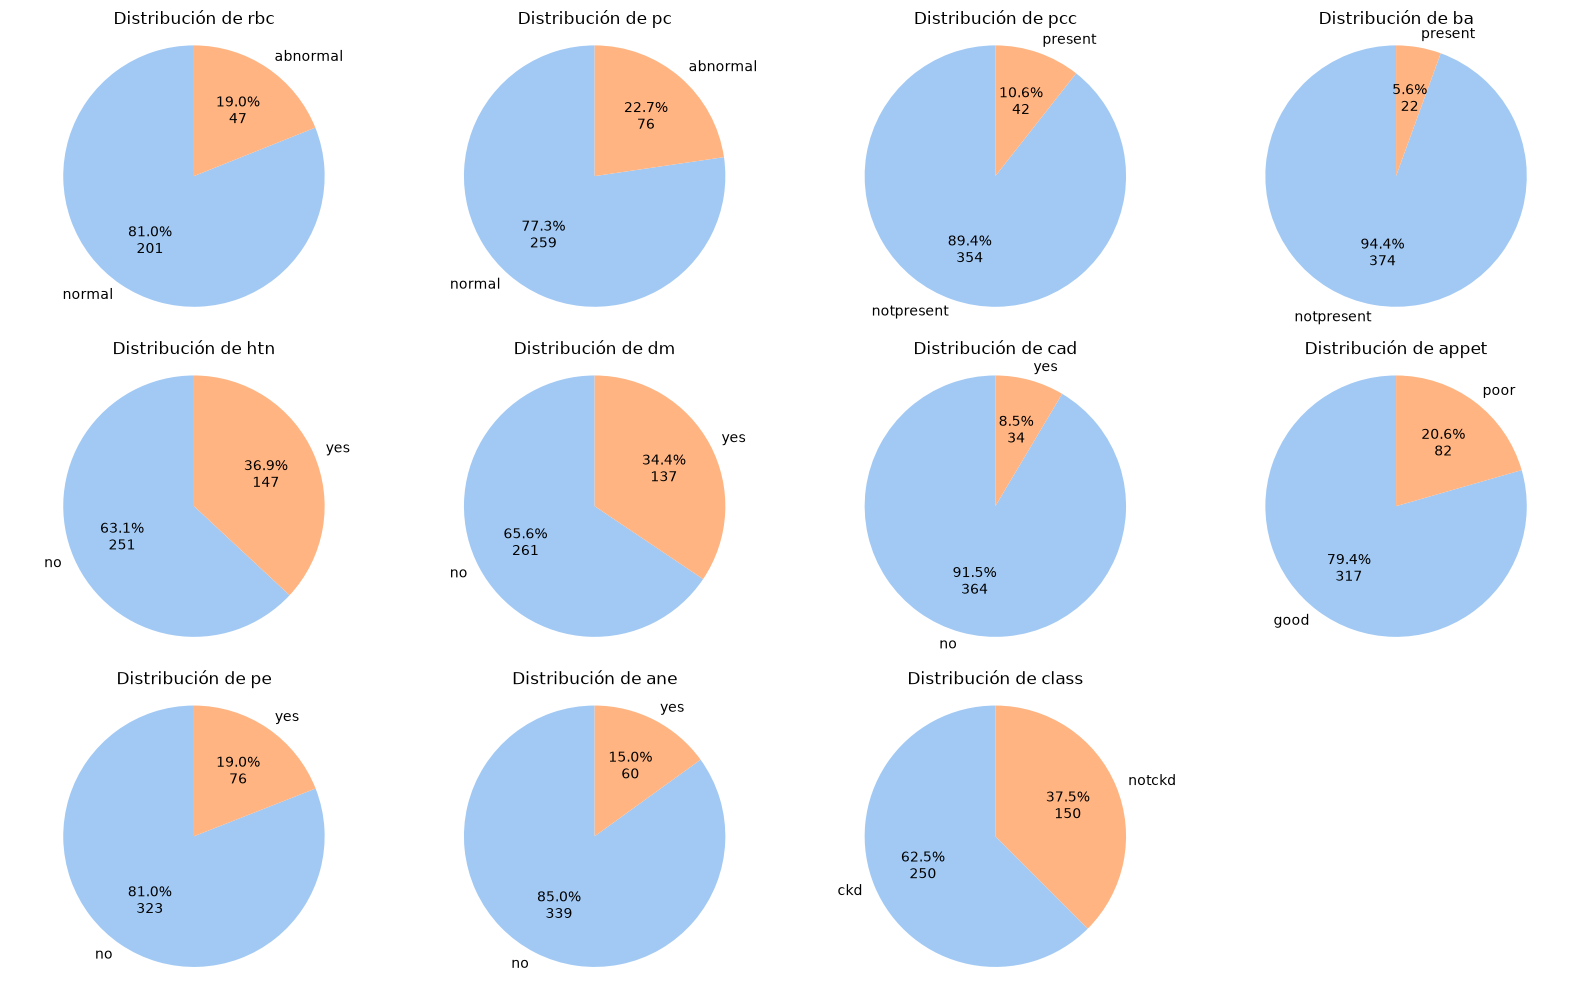

In [255]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

plot_categorical_pie(df=cdk_df, column="rbc", show_values=True, show_percentages=True, ax=axes[0, 0])
plot_categorical_pie(df=cdk_df, column="pc", show_values=True, show_percentages=True, ax=axes[0, 1])
plot_categorical_pie(df=cdk_df, column="pcc", show_values=True, show_percentages=True, ax=axes[0, 2])
plot_categorical_pie(df=cdk_df, column="ba", show_values=True, show_percentages=True, ax=axes[0, 3])
plot_categorical_pie(df=cdk_df, column="htn", show_values=True, show_percentages=True, ax=axes[1, 0])
plot_categorical_pie(df=cdk_df, column="dm", show_values=True, show_percentages=True, ax=axes[1, 1])
plot_categorical_pie(df=cdk_df, column="cad", show_values=True, show_percentages=True, ax=axes[1, 2])
plot_categorical_pie(df=cdk_df, column="appet", show_values=True, show_percentages=True, ax=axes[1, 3])
plot_categorical_pie(df=cdk_df, column="pe", show_values=True, show_percentages=True, ax=axes[2, 0])
plot_categorical_pie(df=cdk_df, column="ane", show_values=True, show_percentages=True, ax=axes[2, 1])
plot_categorical_pie(df=cdk_df, column="class", show_values=True, show_percentages=True, ax=axes[2, 2])

# Ocultar el espacio sin gráfico
axes[2, 3].set_visible(False)

plt.tight_layout()
plt.show()

In [256]:
nominal_entropy = pd.DataFrame(index=nominal_categories)

nominal_entropy["entropy"] = [
    calculate_shannon_entropy(cdk_df, column)[0]
    for column in nominal_categories
]

nominal_entropy.round(3)

,entropy
ane,0.611
appet,0.733
ba,0.310
cad,0.421
class,0.954
dm,0.929
htn,0.950
pc,0.773
pcc,0.488
pe,0.702


Los resultados muestran:

En general, todas las variables muestran predominancia por alguna de sus dos posibles categorias, pero podemos clasificarlas en tres grupos:

- **Variables con baja entropía:** `ba` (0.310), `cad` (0.421) y `pcc` (0.488) presentan distribuciones fuertemente desbalanceadas. Predominan las categorías de ausencia, con proporciones del 94.4%, 91.5% y 89.4%, respectivamente, como se ve en los graficos de torta.
- **Variables con entropía intermedia:** `ane` (0.611), `rbc` (0.700), `pe` (0.702), `appet` (0.733) y `pc` (0.773) muestran una mayor heterogeneidad, aunque todavía predomina una de sus categorías.
- **Variables con entropía elevada:** `dm` (0.929), `htn` (0.950) y `class` (0.954) presentan distribuciones relativamente equilibradas, con proporciones más cercanas entre sus categorías.

En particular, la variable objetivo `class` presenta un 62.5% de pacientes con enfermedad renal crónica (`ckd`) y un 37.5% sin ella (`notckd`). Si bien existe cierto desbalance, su elevada entropía indica una distribución relativamente heterogénea.

En conjunto, las variables categóricas presentan distintos grados de heterogeneidad. Algunas están dominadas por una única categoría, mientras que otras muestran proporciones más equilibradas.

#### 2.2.1. Variables categoricas ordinales

Se analizaron las distribuciones de las variables ordinales sg, al y su mediante gráficos de barras, representando las frecuencias absolutas y relativas de cada categoría. Adicionalmente, se calculó la entropía de Shannon para evaluar la heterogeneidad de sus distribuciones.

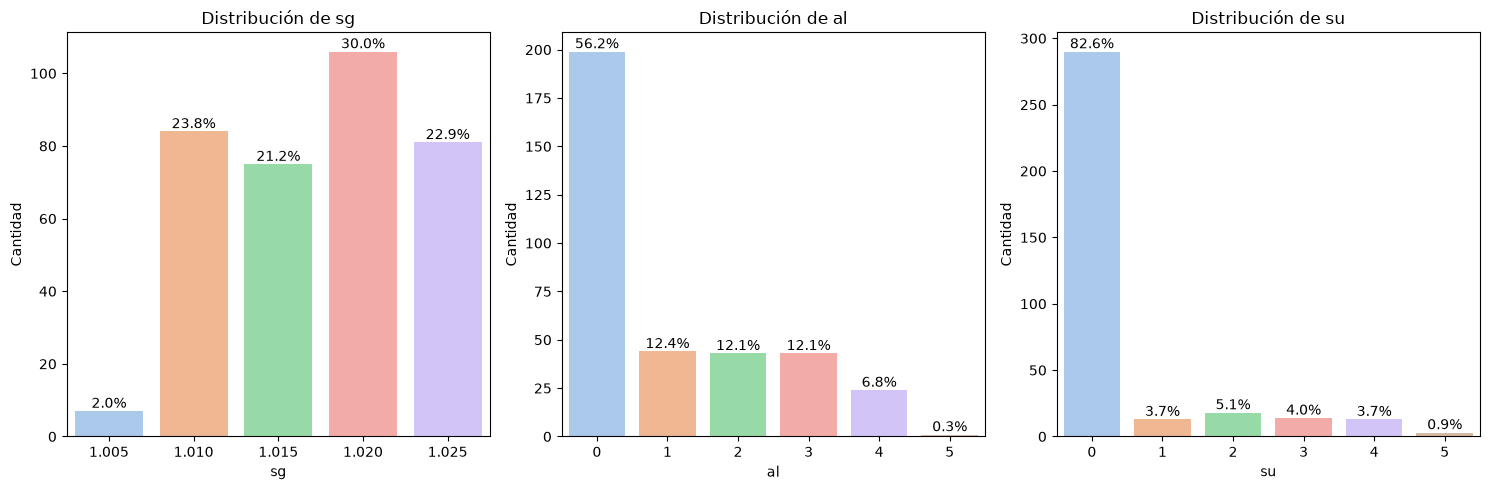

In [257]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

plot_categorical_bar_distribution(df=cdk_df, column="sg", show_values=False, show_percentages=True, order=ordinal_categories["sg"], ax=axes[0])
plot_categorical_bar_distribution(df=cdk_df, column="al", show_values=False, show_percentages=True, order=ordinal_categories["al"], ax=axes[1])
plot_categorical_bar_distribution(df=cdk_df, column="su", show_values=False, show_percentages=True, order=ordinal_categories["su"], ax=axes[2])

plt.tight_layout()
plt.show()

In [258]:
ordinal_entropy = pd.DataFrame(index=ordinal_categories.keys())

ordinal_entropy["entropy"] = [
    calculate_shannon_entropy(cdk_df, column)[0]
    for column in ordinal_categories
]

ordinal_entropy["normalized_entropy"] = [
    calculate_shannon_entropy(cdk_df, column)[1]
    for column in ordinal_categories
]

ordinal_entropy.round(3)

,entropy,normalized_entropy
sg,2.088,0.899
al,1.867,0.722
su,1.044,0.404


Los resultados muestran que:

- **Gravedad específica (`sg`):** presenta la mayor entropía normalizada (0.899), indicando una distribución relativamente equilibrada entre sus cinco categorías. La categoría más frecuente es 1.020 (30%), mientras que 1.005 presenta una frecuencia considerablemente menor (2%).
- **Albúmina (`al`):** presenta una entropía normalizada de 0.722, reflejando una heterogeneidad intermedia. Predomina la categoría 0 (56.2%), mientras que las restantes presentan frecuencias progresivamente menores, especialmente los valores más elevados.
- **Azúcar (`su`):** presenta la menor entropía normalizada (0.404), evidenciando una fuerte concentración en la categoría 0 (82.6%). Las demás categorías tienen una representación considerablemente menor.

En conjunto, `sg` presenta la distribución más heterogénea, seguida de `al`, mientras que `su` muestra un marcado predominio de una única categoría.

## 3. Relaciones entre variables

### Análisis de correlación entre variables numéricas

**Matriz de correlación de Pearson:**

Se calculó la matriz de correlación de Pearson para evaluar la intensidad y dirección de las relaciones lineales entre las variables numéricas del dataset. Los coeficientes cercanos a +1 indican una correlación positiva, mientras que los cercanos a -1 indican una correlación negativa. Los valores próximos a 0 representan relaciones lineales débiles o inexistentes.

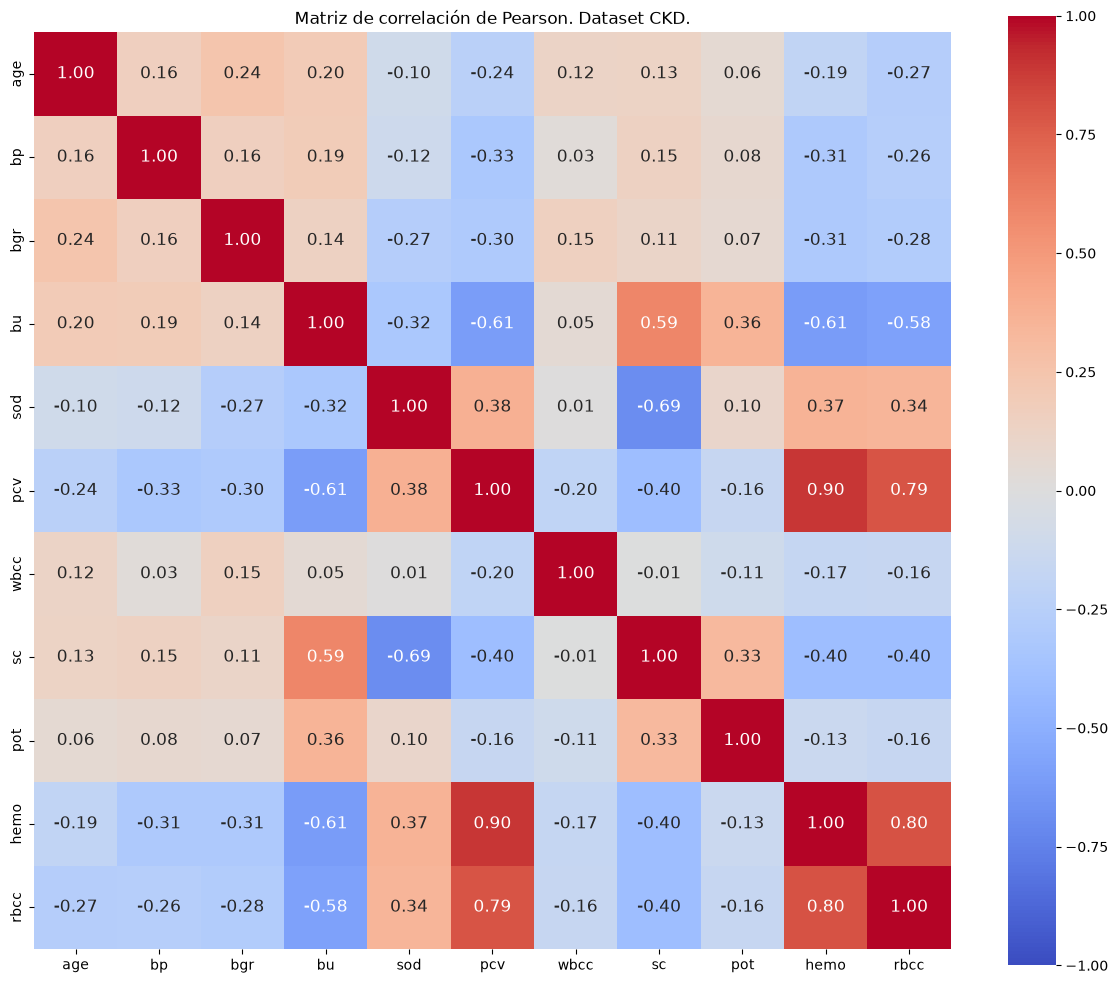

In [259]:
# Matriz de correlación
corr_matrix = cdk_df[numeric_columns].corr()

# Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 12})

plt.title('Matriz de correlación de Pearson. Dataset CKD.')
plt.tight_layout()
plt.show()

A partir de la matriz, se identificaron las siguientes asociaciones destacadas:

- **Hemoglobina (`hemo`), volumen celular (`pcv`) y recuento de glóbulos rojos (`rbcc`):** se observaron correlaciones lineales positivas fuertes a muy fuertes entre estas variables, especialmente entre `hemo` y `pcv` (r = 0.90), `rbcc` y `hemo` (r = 0.80), y `rbcc` y `pcv` (r = 0.79).

- **Urea en sangre (`bu`):** presentó correlaciones lineales negativas moderadas a fuertes con `pcv` (r = -0.61), `hemo` (r = -0.61) y `rbcc` (r = -0.58), y una correlación positiva moderada con creatinina sérica (`sc`, r = 0.59).

- **Creatinina sérica (`sc`):** presentó una correlación lineal negativa fuerte con sodio (`sod`, r = -0.69).

**Matriz de correlación de Spearman:**

Se calculó la matriz de correlación de Spearman para complementar el análisis de Pearson y evaluar posibles asociaciones monótonas entre las variables numéricas, sin requerir que estas sigan una distribución normal.

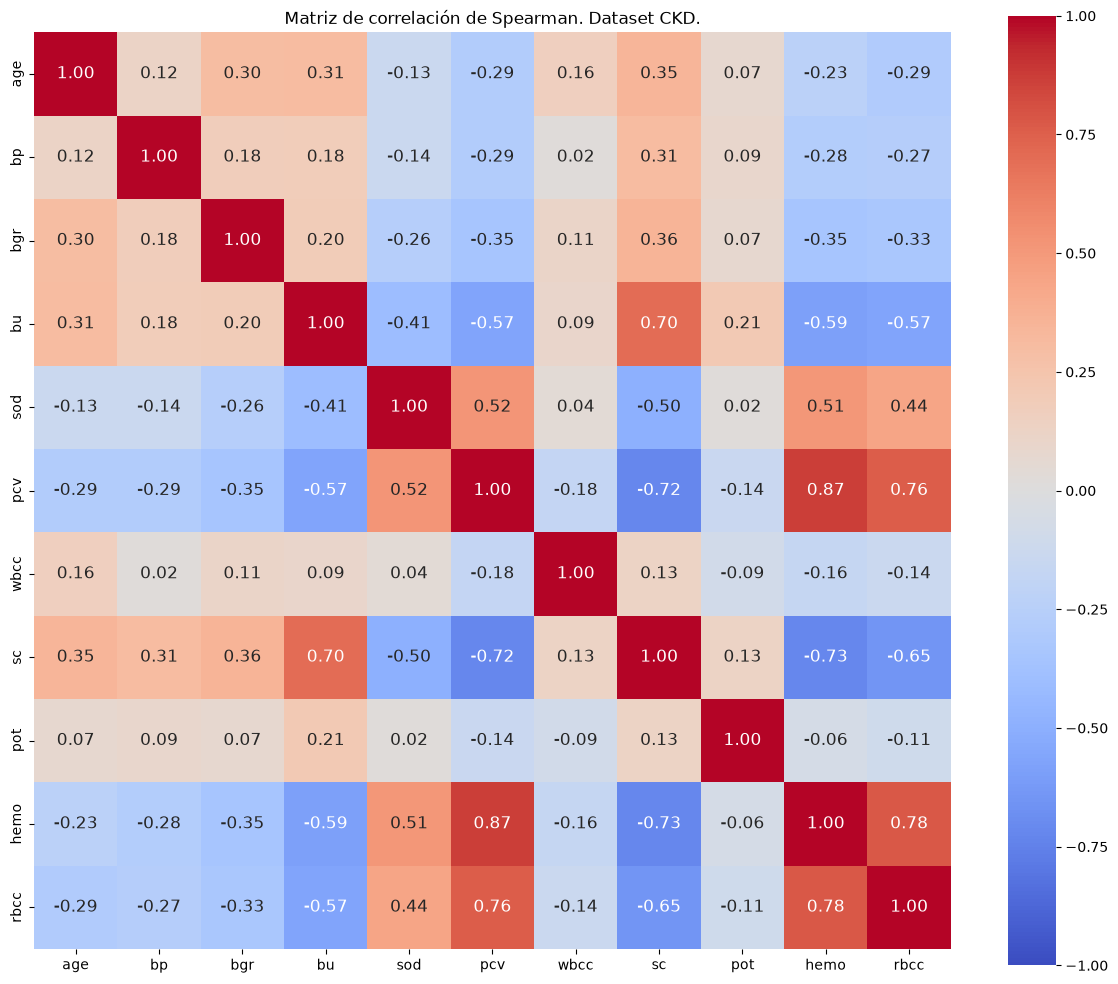

In [260]:
# Matriz de correlación de Spearman
corr_matrix_spearman = cdk_df[numeric_columns].corr(method="spearman")

# Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_spearman, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 12})

plt.title('Matriz de correlación de Spearman. Dataset CKD.')
plt.tight_layout()
plt.show()

Al comparar ambas matrices, se observa que algunas asociaciones mantienen intensidades similares, como las relaciones positivas entre `hemo`, `pcv` y `rbcc`. En cambio, otras presentan diferencias importantes:

- Las relaciones entre `sc` y `pcv` (r = -0.72), `hemo` (r = -0.73) y `rbcc` (r = -0.65) muestran asociaciones negativas más fuertes con Spearman que con Pearson.
- La relación entre `sc` y `bu` también aumenta su intensidad (r = 0.70).
- En cambio, la asociación entre `sc` y `sod` disminuye de -0.69 con Pearson a -0.50 con Spearman.

Estas diferencias sugieren que algunas asociaciones podrían presentar patrones monótonos que no se describen completamente mediante una relación lineal.

**Graficos de dispersión:**

Para caracterizar mejor el comportamiento de las relaciones entre variables que parecieran tener una correlacion monotona y/o lineal entre ellas se suma al analisis gráficos de dispersión.

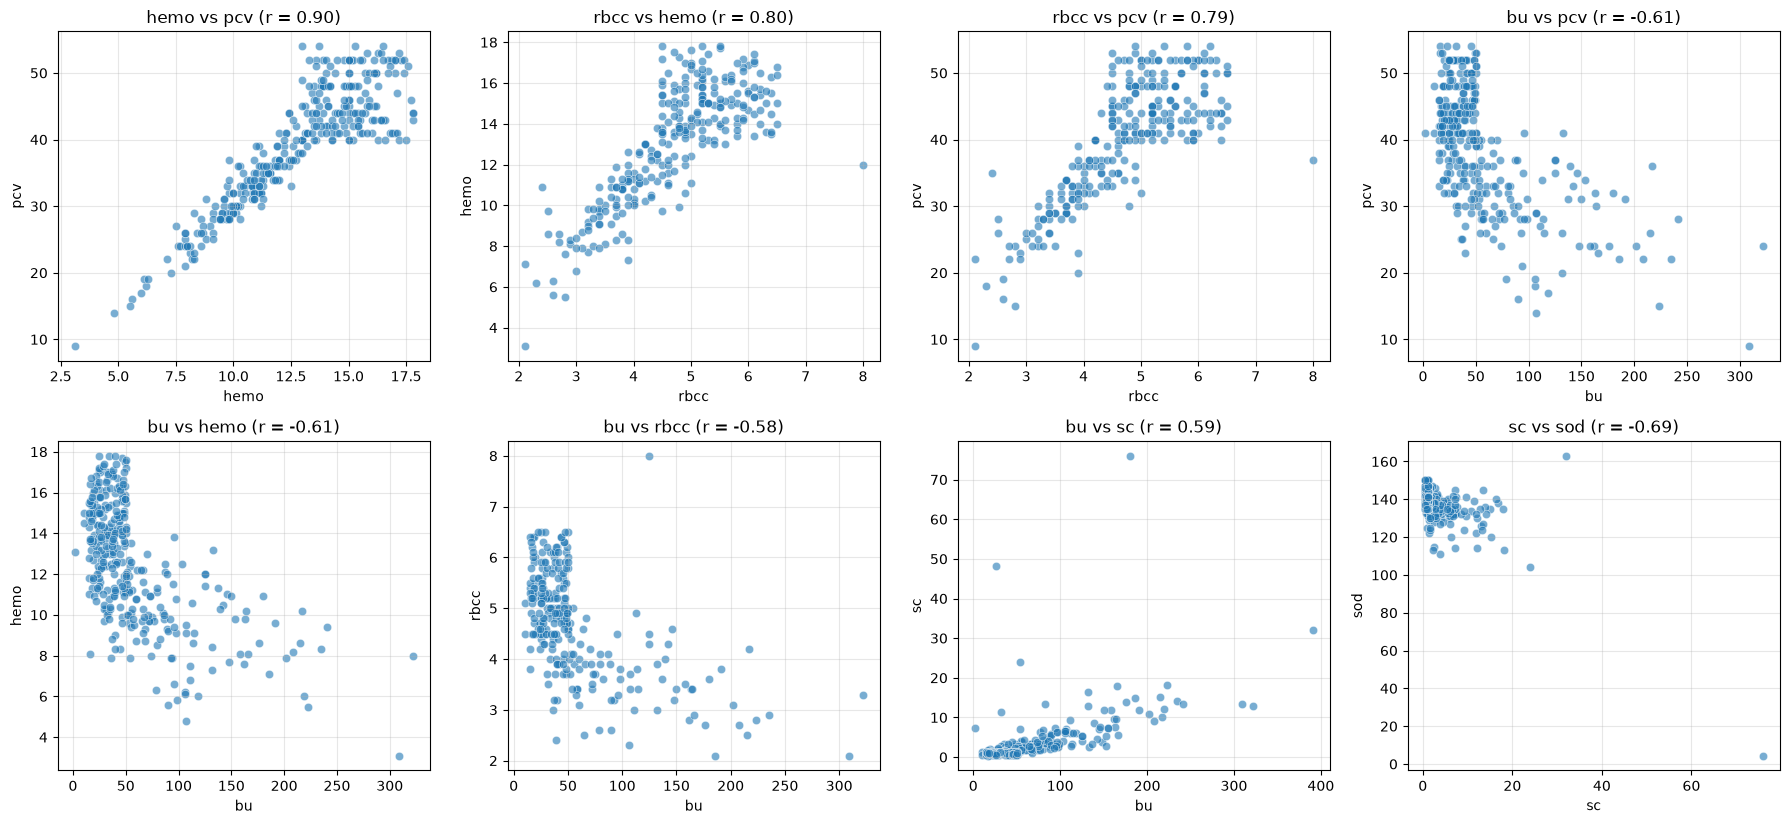

In [261]:
pairs = [
    ('hemo', 'pcv'), ('rbcc', 'hemo'), ('rbcc', 'pcv'),
    ('bu', 'pcv'), ('bu', 'hemo'), ('bu', 'rbcc'), ('bu', 'sc'),
    ('sc', 'sod')
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, (x, y) in zip(axes.flat, pairs):
    sns.scatterplot(data=cdk_df, x=x, y=y, ax=ax, alpha=0.6)
    r = cdk_df[[x, y]].corr().iloc[0, 1]
    ax.set_title(f'{x} vs {y} (r = {r:.2f})')
    ax.grid(alpha=0.3)

for ax in axes.flat[len(pairs):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


Los gráficos de dispersión permiten corroborar visualmente las asociaciones identificadas en las matrices de correlación.

Las relaciones entre `hemo`, `pcv` y `rbcc` presentan tendencias positivas aproximadamente lineales, consistentes con los coeficientes elevados de Pearson y Spearman.

En cambio, las relaciones de `sc` con `pcv`, `hemo`, `rbcc` y `bu` muestran tendencias monótonas que no parecen estrictamente lineales, junto con valores extremos. Esto es consistente con las correlaciones de mayor magnitud obtenidas mediante Spearman.

Por último, la relación entre `sc` y `sod` presenta una observación extremadamente atípica que podría influir considerablemente en Pearson, explicando parcialmente por qué su correlación es más fuerte que la obtenida mediante Spearman.